In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import matplotlib.pyplot as plt
import seaborn as sns

import os,sys
from pathlib import Path
from tqdm import tqdm
import warnings

In [2]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
import rpy2

In [3]:
adata = sc.read_h5ad('/root/workspace/STWaveGraph-main/Data/adata.h5ad')
adata.var_names_make_unique()

In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516

In [5]:
n_clusters=8

In [6]:
model = STWaveGraph(
    adata=adata,
    n_clusters=8,
    device=device,

    n_top_genes=2200,
    pca_dim=36,
    n_neighbors_spatial=16,
    expr_power=1.10,
    random_seed=821,

    pretrain_epochs=300,
    finetune_epochs=180,
    # use_q_for_pred=True, # 开启新方案

    lambda_rec=0.3,
    lambda_ssl=0.5,
    lambda_smooth=0.08,
    lambda_kl=0.90,
    lambda_q_cons=0.25,
    lambda_balance=0.06,
    lambda_boundary=0.12,

    refine_iters=25
)
adata = model.train(verbose=True)

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/scanpy/preprocessing/_highly_variable_genes.py:62: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(


========== Stage 1: Representation Pretraining ==========


100%|██████████| 300/300 [00:24<00:00, 12.04it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 28%|██▊       | 51/180 [00:04<00:11, 11.55it/s]

...

[Finetune] Epoch 100/180 | loss=0.3846 | rec=0.6948 | ssl=0.1547 | smooth=0.2237 | kl=0.0493 | balance=0.0043 | bd=0.3006 | extra_reg_on=1


 84%|████████▍ | 151/180 [00:13<00:02, 11.59it/s]

[Finetune] Epoch 150/180 | loss=0.3641 | rec=0.6526 | ssl=0.1201 | smooth=0.2261 | kl=0.0600 | balance=0.0038 | bd=0.2978 | extra_reg_on=1


100%|██████████| 180/180 [00:15<00:00, 11.43it/s]


INFO: Using external clustering ('mclust') on embedding (h) for prediction.
fitting ...
  |======================================================================| 100%


In [7]:
adata

AnnData object with n_obs × n_vars = 5488 × 155
    obs: 'celltype', 'cluster', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [8]:
adata.obsm['emb']

array([[ 0.00834555, -0.23182599,  0.19459802, ...,  0.08672161,
         0.09864108, -0.05948974],
       [ 0.09845636, -0.22550018,  0.10956598, ...,  0.24134351,
         0.13592717, -0.05910896],
       [ 0.04180978, -0.1743474 ,  0.11954201, ...,  0.30023897,
         0.09850261, -0.025422  ],
       ...,
       [ 0.06406545,  0.13737251,  0.27485102, ...,  0.08020178,
        -0.18052815, -0.2188003 ],
       [ 0.00374147,  0.12013138,  0.19003585, ...,  0.0873694 ,
        -0.14195049, -0.29346925],
       [ 0.00387738,  0.23351723,  0.12441859, ..., -0.01962654,
        -0.1368296 , -0.14032058]], dtype=float32)

In [9]:
# # filter out NA nodes
# adata = adata[~pd.isnull(adata.obs['ground_truth'])]

# # calculate metric ARI
# ARI = metrics.adjusted_rand_score(adata.obs['pred_domain'], adata.obs['ground_truth'])
# adata.uns['ARI'] = ARI

# print('Dataset:', dataset)
# print('ARI:', ARI)

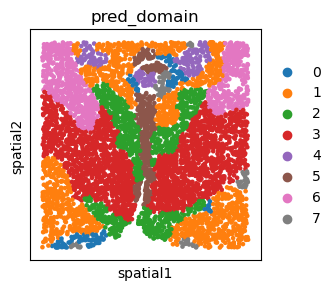

In [10]:
fig, ax = plt.subplots(1,1,figsize=(4*1,3))
sc.pl.spatial(adata, color='pred_domain', spot_size=40, show=False, ax=ax)
ax.invert_yaxis()

In [11]:
adata

AnnData object with n_obs × n_vars = 5488 × 155
    obs: 'celltype', 'cluster', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs', 'pred_domain_colors'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

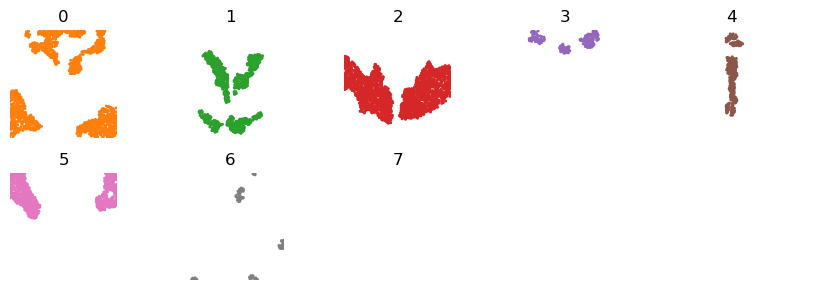

In [12]:
fig, axes = plt.subplots(2,5,figsize=(1.7*5, 1.5*2), sharex=True, sharey=True)
axes = axes.ravel()

for i in range(n_clusters):
    sub = adata[adata.obs['pred_domain'] == str(i + 1)]
    sc.pl.spatial(sub, spot_size=50, color='pred_domain', ax=axes[i], legend_loc=None, show=False)
    axes[i].set_title(i)
    
    
xmin = adata.obsm['spatial'][:, 0].min()
xmax = adata.obsm['spatial'][:, 0].max()
ymin = adata.obsm['spatial'][:, 1].min()
ymax = adata.obsm['spatial'][:, 1].max()

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xlim([xmin, xmax])
    ax.set_ylim([ymin, ymax])
    
plt.subplots_adjust(wspace=0, hspace=0.05)
plt.tight_layout()


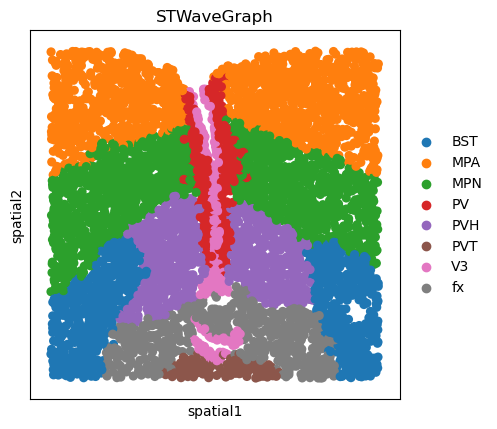

In [13]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["cluster"],
    title=["STWaveGraph"],
    spot_size=50,
    show=True
)


In [14]:
adata

AnnData object with n_obs × n_vars = 5488 × 155
    obs: 'celltype', 'cluster', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs', 'pred_domain_colors', 'cluster_colors'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [15]:
# filter out NA nodes
adata = adata[~pd.isnull(adata.obs['cluster'])]

# calculate metric ARI
ARI = metrics.adjusted_rand_score(adata.obs['pred_domain'], adata.obs['cluster'])
adata.uns['ARI'] = ARI


print('ARI:', ARI)

ARI: 0.4404250705455448


/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


In [22]:
from sklearn import metrics
import pandas as pd

# filter out NA nodes 
# [修复警告]：加上 .copy() 将视图变为独立对象，消除底部的红字警告
adata = adata[~pd.isnull(adata.obs['cluster'])].copy()

# ==========================================
# 计算指标: ARI 和 NMI
# ==========================================
# 提取列，统一转为字符串保证计算安全
y_true = adata.obs['cluster'].astype(str)
y_pred = adata.obs['pred_domain'].astype(str)

# 1. 计算 metric ARI
ARI = metrics.adjusted_rand_score(y_true, y_pred)
adata.uns['ARI'] = ARI
print('ARI:', ARI)

# 2. 计算 metric NMI
NMI = metrics.normalized_mutual_info_score(y_true, y_pred)
adata.uns['NMI'] = NMI
print('NMI:', NMI)

ARI: 0.4404250705455448
NMI: 0.5168451449981792


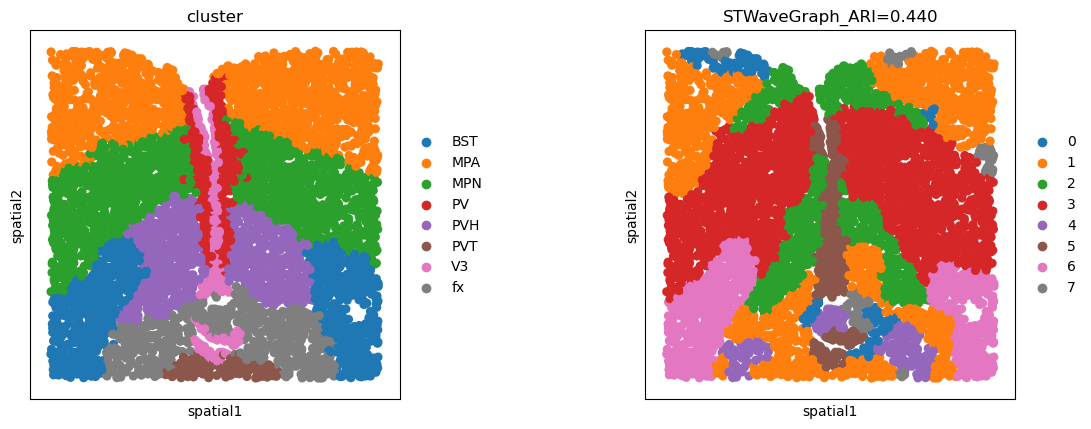

In [16]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["cluster", "pred_domain"],
    title=["cluster", f"STWaveGraph_ARI={ARI:.3f}"],
    spot_size=50,
    show=True
)


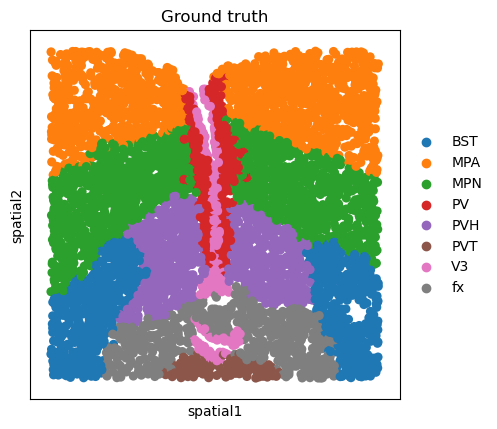

In [18]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["cluster"],
    title=["Ground truth"],
    spot_size=50,
    show=True
)

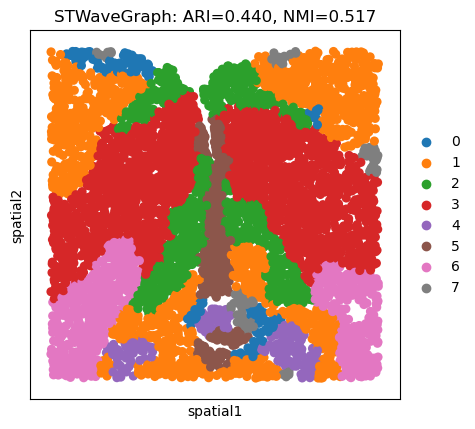

In [24]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["pred_domain"],
    title=[f"STWaveGraph: ARI={ARI:.3f}, NMI={NMI:.3f}"],
    spot_size=50,
    show=True
)


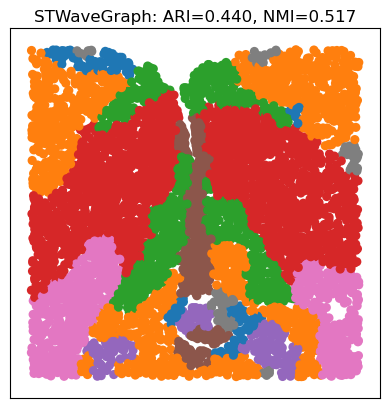

In [25]:

import matplotlib.pyplot as plt
# plotting spatial clustering result 
sc.pl.spatial(adata, 
              img_key="hires", 
              color=["pred_domain"],
              title=["STWaveGraph (ARI=%.5f)"%ARI],
              legend_loc=None,
              spot_size=50,
              show=False,)  

# 获取当前图形和坐标轴
fig = plt.gcf()
ax = plt.gca()

# 去掉 x 和 y 轴的标签
ax.set_xlabel('')
ax.set_ylabel('')

# 添加新的标题
plt.title(f"STWaveGraph: ARI={ARI:.3f}, NMI={NMI:.3f}", pad=5)  # pad 用于调整标题与图形的距离

# 显示图形
plt.show()